In [21]:
from cwfc.data import load_readings, build_targets, split_train_holdout
series = build_targets(load_readings("../challenge_data"))
train, holdout = split_train_holdout(series)
print(len(train), len(holdout))

110 24


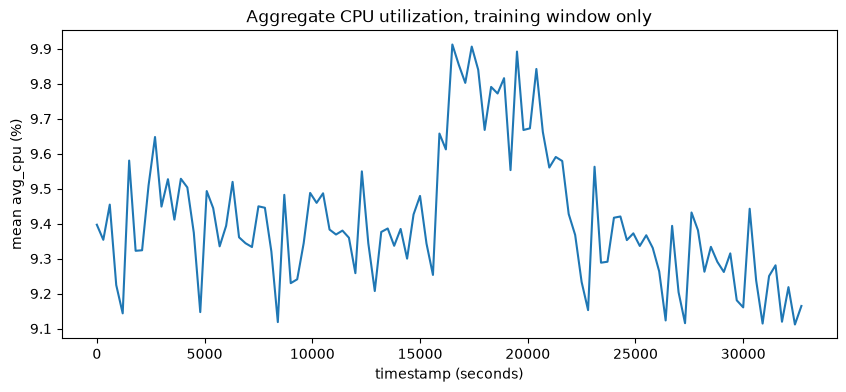

count    110.000000
mean       9.414089
std        0.193568
min        9.111634
25%        9.288952
50%        9.378121
75%        9.507673
max        9.912175
Name: aggregate_cpu_utilization, dtype: float64

mean |change| per 5-min step: 0.1211
largest single-step change:   0.4368


In [22]:
import matplotlib.pyplot as plt

y = train["aggregate_cpu_utilization"]

# 1. The plot
plt.figure(figsize=(10, 4))
plt.plot(train["timestamp"], y)
plt.xlabel("timestamp (seconds)")
plt.ylabel("mean avg_cpu (%)")
plt.title("Aggregate CPU utilization, training window only")
plt.show()

# 2. Level and spread
print(y.describe())

# 3. How much does it move from one step to the next?
step_change = y.diff().abs()
print("\nmean |change| per 5-min step:", round(step_change.mean(), 4))
print("largest single-step change:  ", round(step_change.max(), 4))

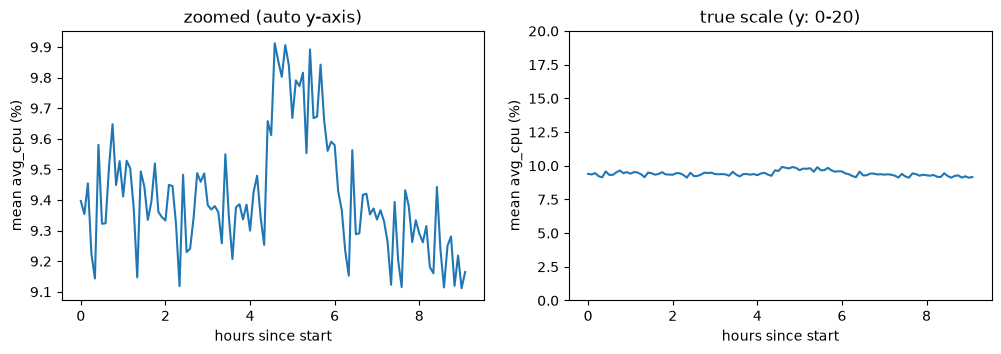

In [23]:
hours = train["timestamp"] / 3600

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(hours, y);          ax[0].set_title("zoomed (auto y-axis)")
ax[1].plot(hours, y);          ax[1].set_ylim(0, 20); ax[1].set_title("true scale (y: 0-20)")
for a in ax:
    a.set_xlabel("hours since start"); a.set_ylabel("mean avg_cpu (%)")
plt.show()

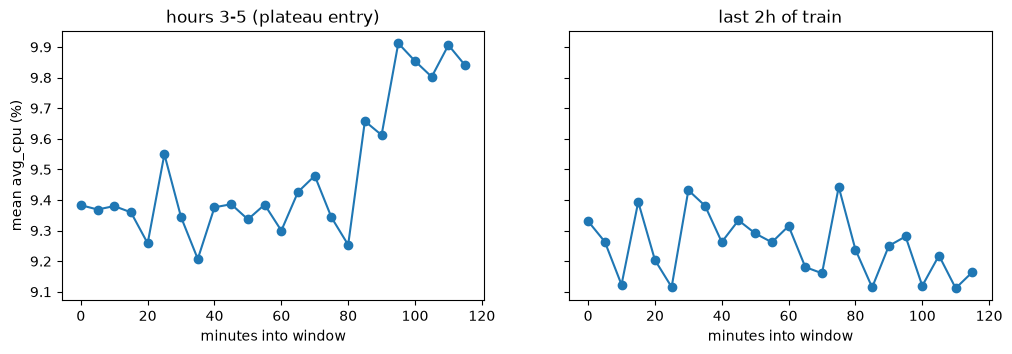

            mean    std  count
timestamp                     
0          9.411  0.147     12
1          9.405  0.107     12
2          9.367  0.122     12
3          9.361  0.081     12
4          9.616  0.248     12
5          9.707  0.113     12
6          9.372  0.124     12
7          9.295  0.103     12
8          9.239  0.091     12
9          9.138  0.037      2


In [24]:


fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, (lo, hi, title) in zip(ax, [(36, 60, "hours 3-5 (plateau entry)"),
                                    (86, 110, "last 2h of train")]):
    seg = train.iloc[lo:hi]
    minutes = (seg["timestamp"] - seg["timestamp"].iloc[0]) / 60
    a.plot(minutes, seg["aggregate_cpu_utilization"], marker="o")
    a.set_title(title); a.set_xlabel("minutes into window")
ax[0].set_ylabel("mean avg_cpu (%)")
plt.show()

# Quantify your plateau observation: mean level per hour of the training window
h = (train["timestamp"] // 3600).astype(int)
print(train.groupby(h)["aggregate_cpu_utilization"].agg(["mean", "std", "count"]).round(3))

In [25]:
from cwfc.baselines import persistence_forecast, moving_average_forecast, seasonal_naive_forecast
from cwfc.evaluate import index_splits, rolling_origin_eval

T = "aggregate_cpu_utilization"
forecasters = {
    "persistence": persistence_forecast,
    "moving_avg_6": lambda tr, tp, t: moving_average_forecast(tr, tp, t, 6),
    "moving_avg_12": lambda tr, tp, t: moving_average_forecast(tr, tp, t, 12),
    "seasonal_naive_12": lambda tr, tp, t: seasonal_naive_forecast(tr, tp, t, 12),
}

print("splits (train_end, val_end):", index_splits(len(train)))
res = rolling_origin_eval(train, T, forecasters)
summary = res.groupby("model")[["mae", "rmse"]].mean()
summary["mae_vs_persistence"] = summary["mae"] / summary.loc["persistence", "mae"]
print(summary.sort_values("mae"))

splits (train_end, val_end): [(50, 74), (62, 86), (74, 98), (86, 110)]
                        mae      rmse  mae_vs_persistence
model                                                    
persistence        0.205614  0.238734            1.000000
moving_avg_12      0.254464  0.282340            1.237583
seasonal_naive_12  0.263428  0.297096            1.281176
moving_avg_6       0.265921  0.297189            1.293300


In [26]:
print(res.pivot(index="fold", columns="model", values="mae").round(3))

model  moving_avg_12  moving_avg_6  persistence  seasonal_naive_12
fold                                                              
0              0.324         0.316        0.268              0.316
1              0.220         0.312        0.297              0.281
2              0.355         0.296        0.124              0.355
3              0.119         0.140        0.132              0.102


In [27]:
from cwfc.models import ses_forecast

cands = {"persistence": persistence_forecast}
for a in [0.3, 0.5, 0.7, 0.9]:
    cands[f"ses_{a}"] = (lambda a: lambda tr, tp, t: ses_forecast(tr, tp, t, a))(a)

res2 = rolling_origin_eval(train, T, cands)
print(res2.pivot(index="fold", columns="model", values="mae").round(3))
s2 = res2.groupby("model")[["mae", "rmse"]].mean()
s2["mae_vs_persistence"] = s2["mae"] / s2.loc["persistence", "mae"]
print(s2.sort_values("mae").round(3))

model  persistence  ses_0.3  ses_0.5  ses_0.7  ses_0.9
fold                                                  
0            0.268    0.317    0.307    0.294    0.278
1            0.297    0.280    0.285    0.282    0.290
2            0.124    0.254    0.202    0.167    0.138
3            0.132    0.131    0.128    0.128    0.131
               mae   rmse  mae_vs_persistence
model                                        
persistence  0.206  0.239               1.000
ses_0.9      0.209  0.241               1.017
ses_0.7      0.218  0.249               1.060
ses_0.5      0.230  0.261               1.120
ses_0.3      0.245  0.276               1.194


In [28]:
import pandas as pd
import numpy as np
rows = []
for k, (a, b) in enumerate(index_splits(len(train))):
    fit, val = train.iloc[:a], train.iloc[a:b]
    pred = persistence_forecast(fit, val, T)
    for step, (act, p) in enumerate(zip(val[T], pred), start=1):
        rows.append({"fold": k, "step": step, "actual": act, "pred": p})
err = pd.DataFrame(rows)
err["error"] = err["actual"] - err["pred"]      # positive = we UNDER-forecast
err["abs_error"] = err["error"].abs()

print("overall MAE:", err.abs_error.mean().round(3), "| RMSE:", np.sqrt((err.error**2).mean()).round(3))

# 1. Peak vs normal (peak = actual above the 75th percentile of the training window)
cut = train[T].quantile(0.75)
err["peak"] = err["actual"] > cut
print("\npeak cutoff:", round(cut, 3))
print(err.groupby("peak").agg(n=("error", "size"), mae=("abs_error", "mean"), bias=("error", "mean")).round(3))

# 2. Error by how far ahead we forecast
print("\nMAE by horizon (steps ahead):")
print(err.groupby(pd.cut(err.step, [0, 6, 12, 18, 24]), observed=True)["abs_error"].mean().round(3))

# 3. Safety margin: how much extra capacity covers X% of cases?
print("\nunder-forecast share:", (err.error > 0).mean().round(2))
for q in (0.8, 0.9, 0.95):
    m = err["error"].quantile(q)
    print(f"margin for ~{int(q*100)}% coverage: +{m:.3f} points")

overall MAE: 0.206 | RMSE: 0.254

peak cutoff: 9.508
        n    mae  bias
peak                  
False  63  0.187 -0.18
True   33  0.240  0.15

MAE by horizon (steps ahead):
step
(0, 6]      0.150
(6, 12]     0.174
(12, 18]    0.279
(18, 24]    0.219
Name: abs_error, dtype: float64

under-forecast share: 0.32
margin for ~80% coverage: +0.134 points
margin for ~90% coverage: +0.296 points
margin for ~95% coverage: +0.414 points
